[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/06_bias_variance_cv.ipynb)

# 06 · Bias–Variance & Cross-Validation: Measuring What Actually Matters

**Part 1 — Classical supervised learning** · Notebook 6 of 27

Notebook 05 ended with a warning: training error can be driven to zero by a model that is useless on new data. So what *should* we measure, and how do we measure it without fooling ourselves? This notebook answers both. First the theory: the error on new data splits exactly into **bias², variance and noise**, and we'll watch each piece move as models get more flexible. Then the practice: **cross-validation**, the standard way to choose models and hyperparameters, and **data leakage**, the standard way to fool yourself while doing it.

**What you'll learn**

1. Why training error lies: empirical risk vs. true risk
2. The best possible predictor, $h(x) = \mathbb{E}[y \mid x]$, and the noise floor
3. The **bias–variance decomposition**, derived and then simulated
4. Bias and variance for ridge regression
5. Why complex models also become numerically unstable
6. Holding out data: train / validation / test
7. **Learning curves**: is more data going to help?
8. **K-fold cross-validation**, from scratch, for choosing degree and $\lambda$
9. **Data leakage**: how to get 90% "accuracy" on pure noise
10. Beyond the U-curve: **double descent**

*Course map: ISYE 4600 W6 (Bias–Variance Tradeoff & Cross Validation) and HW2 Q1; CX 4240 Lecture 6 (polynomial overfitting, choosing $\lambda$).*

In [1]:
#@title ⚙️ Setup — run this cell first (imports, plot style, helpers)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display, Markdown
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, IntSlider

# One consistent, colorblind-checked palette used across the whole series
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#4a3aa7", red="#e34948",
         ink="#0b0b0b", muted="#52514e", light="#d9d8d3")
plt.rcParams.update({
    "figure.figsize": (6.4, 4.2), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
        ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
    "lines.linewidth": 2, "font.size": 11, "legend.frameon": False,
    "animation.embed_limit": 40, "animation.frame_format": "jpeg",   # JPEG frames keep notebooks small
})

def show_anim(anim):
    """Render a matplotlib animation as an interactive player (play / pause / scrub)."""
    plt.close(anim._fig)
    return HTML(anim.to_jshtml(default_mode="once"))

rng = np.random.default_rng(0)
print("Setup complete ✓")
from sklearn.datasets import load_diabetes
print("Ready ✓")

def poly(x, d):
    """Design matrix with columns 1, x, ..., x^d."""
    return np.vander(x, d + 1, increasing=True)

def fit_ridge(Phi, y, lam=0.0):
    """Least squares (lam = 0) or ridge with an unpenalized intercept, as in notebook 05.
    Solved as an augmented least-squares problem (QR/SVD inside lstsq) rather than via XᵀX,
    because XᵀX squares the condition number and high-degree polynomials are already ill-conditioned."""
    m_, p_ = Phi.shape
    if lam == 0:
        return np.linalg.lstsq(Phi, y, rcond=None)[0]
    P = np.sqrt(lam * m_) * np.eye(p_)[1:]          # rows √(λm)·e_j for j ≥ 1: penalize all but the intercept
    return np.linalg.lstsq(np.vstack([Phi, P]), np.r_[y, np.zeros(p_ - 1)], rcond=None)[0]

# The running example from notebook 05: noisy samples of sin(2πx)
f_true = lambda x: np.sin(2 * np.pi * x)
NOISE = 0.25
def sample(m, rng):
    x = rng.uniform(0, 1, m)
    return x, f_true(x) + rng.normal(0, NOISE, m)

Setup complete ✓


Ready ✓


---
## 1. Why training error lies

When we fit a model, we minimize the **empirical risk**, the average loss on the $m$ training points:

$$\hat L(f) = \frac1m\sum_{i=1}^m \big(y^i - f(x^i)\big)^2$$

But what we actually care about is the **true risk** (or *generalization error*): the expected loss on a *new* point drawn from the same distribution as the data,

$$L(f) = \mathbb{E}_{(x, y)}\Big[\big(y - f(x)\big)^2\Big]$$

The empirical risk is an estimate of the true risk, and for a fixed $f$ chosen *before* seeing the data, it's a fine one (it's an average, so the law of large numbers kicks in). The trouble is that we *chose* $f$ to make the empirical risk small on exactly these points. The model has seen the answers, so its score on them is optimistic. How optimistic depends on how flexible the model is:

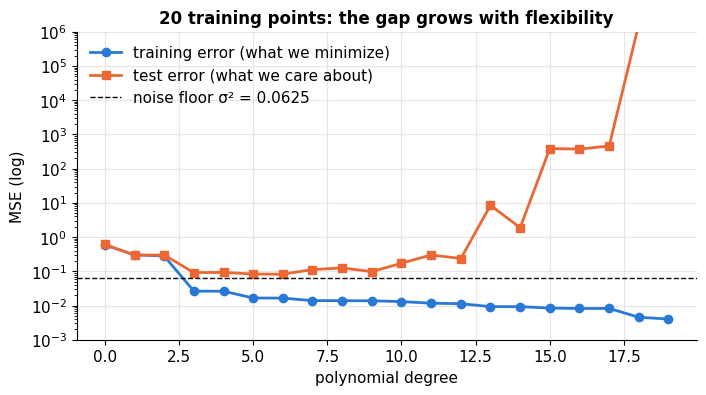

In [2]:
rng = np.random.default_rng(0)
x_tr, y_tr = sample(20, rng)
x_te, y_te = sample(5000, rng)              # a big fresh sample ≈ the true risk

degrees = range(0, 20)
tr_err, te_err = [], []
for d in degrees:
    th = fit_ridge(poly(x_tr, d), y_tr)
    tr_err.append(np.mean((poly(x_tr, d) @ th - y_tr) ** 2))
    te_err.append(np.mean((poly(x_te, d) @ th - y_te) ** 2))

fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogy(degrees, tr_err, "-o", color=C["blue"], label="training error (what we minimize)")
ax.semilogy(degrees, te_err, "-s", color=C["orange"], label="test error (what we care about)")
ax.axhline(NOISE**2, color=C["ink"], ls="--", lw=1, label=f"noise floor σ² = {NOISE**2}")
ax.set(xlabel="polynomial degree", ylabel="MSE (log)", ylim=(1e-3, 1e6), title="20 training points: the gap grows with flexibility")
ax.legend(); plt.show()

Training error only goes down as the degree grows. (In exact arithmetic it would hit zero at degree 19: 20 coefficients for 20 points, enough to pass through every one. In floating point it stalls a bit above zero, because the columns $x^{15}, x^{16}, \dots$ become numerically indistinguishable; section 5 shows why.) Test error goes down, bottoms out around degree 3–9, then shoots up by orders of magnitude. And notice the dashed line: test error **never goes below $\sigma^2 = 0.0625$**, no matter what. Section 2 explains why.

> 🤔 **Question: Why not just pick the degree with the lowest test error from this plot?**
>
> Because then the test set has been used to make a decision, so it's no longer an unbiased estimate of performance on new data. With enough tries you'd find a model that happens to do well on this particular test set. The honest procedure, choosing with **validation** data and touching the test set once at the very end, is section 8.

---
## 2. The best possible predictor, and the noise floor

Suppose we knew the true distribution $p(x, y)$ exactly. What prediction $f(x)$ minimizes the expected squared error? ISYE 4600 (W6) derives it. Write the true risk as an integral and differentiate with respect to the value $f(x)$ at one particular $x$:

$$\frac{\partial}{\partial f(x)}\iint \big(y - f(x)\big)^2 p(x, y)\,dx\,dy = -2\int \big(y - f(x)\big)\,p(x, y)\,dy = 0$$

$$\Longrightarrow\quad f(x)\,p(x) = \int y\,p(x, y)\,dy \quad\Longrightarrow\quad f(x) = \int y\,p(y\mid x)\,dy = \mathbb{E}[y \mid x]$$

The best possible predictor is the **conditional mean**: $h(x) = \mathbb{E}[y\mid x]$, the average of all the $y$'s you'd ever see at that $x$. (ISYE's example: if at 2 study hours you've seen exam scores 8, 10 and 12, predict 10.)

Even $h$ makes mistakes, because $y$ is random around its mean. Its expected error is the **irreducible noise**:

$$\mathbb{E}\big[(y - h(x))^2\big] = \mathbb{E}_x\big[\text{Var}(y \mid x)\big] = \sigma^2 \quad\text{(in our example)}$$

No model, however clever, can beat this, because the information to do better isn't in $x$. For our sine data, $h(x) = \sin(2\pi x)$ and the noise floor is $0.25^2 = 0.0625$.

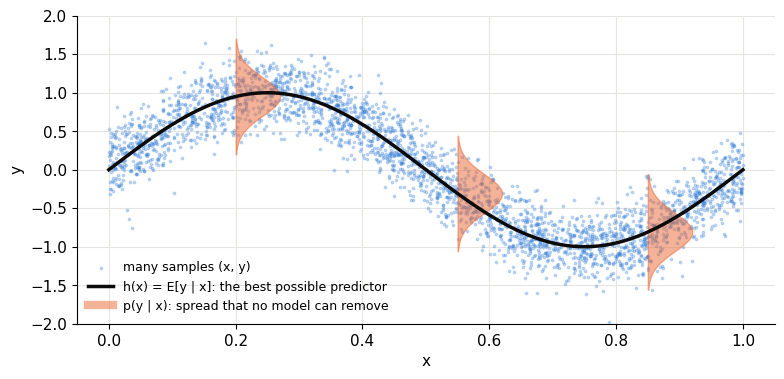

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
xs_big = rng.uniform(0, 1, 3000)
ax.scatter(xs_big, f_true(xs_big) + rng.normal(0, NOISE, 3000), s=3, color=C["blue"], alpha=0.25, label="many samples (x, y)")
xx = np.linspace(0, 1, 300)
ax.plot(xx, f_true(xx), color=C["ink"], lw=2.5, label="h(x) = E[y | x]: the best possible predictor")
for x0 in [0.2, 0.55, 0.85]:
    yy = np.linspace(-3 * NOISE, 3 * NOISE, 100)
    dens = np.exp(-yy**2 / (2 * NOISE**2))
    ax.fill_betweenx(f_true(x0) + yy, x0, x0 + 0.07 * dens, color=C["orange"], alpha=0.5)
ax.plot([], [], color=C["orange"], lw=6, alpha=0.5, label="p(y | x): spread that no model can remove")
ax.set(xlabel="x", ylabel="y", ylim=(-2, 2)); ax.legend(loc="lower left", fontsize=9); plt.show()

---
## 3. The bias–variance decomposition

Now the realistic case. Our predictor $\hat f$ is learned from a random training set $\mathcal{D}$, so $\hat f$ itself is **random**: a different training set gives a different fit (notebook 05, section 9). Let $\bar f(x) = \mathbb{E}_{\mathcal D}[\hat f(x)]$ be the **average prediction** at $x$ over all possible training sets. Then the expected test error, averaged over both the training set and the test point, splits into three terms:

$$\underbrace{\mathbb{E}_{\mathcal D}\,\mathbb{E}_{x,y}\Big[\big(y - \hat f(x)\big)^2\Big]}_{\text{expected test error}} \;=\; \underbrace{\mathbb{E}_x\Big[\big(\bar f(x) - h(x)\big)^2\Big]}_{\text{bias}^2} \;+\; \underbrace{\mathbb{E}_x\,\mathbb{E}_{\mathcal D}\Big[\big(\hat f(x) - \bar f(x)\big)^2\Big]}_{\text{variance}} \;+\; \underbrace{\mathbb{E}\Big[\big(y - h(x)\big)^2\Big]}_{\text{noise } \sigma^2}$$

**Derivation** (the same two-step trick, used twice). Fix $x$. First add and subtract $h(x)$:

$$\big(y - \hat f\big)^2 = \big(y - h\big)^2 + \big(h - \hat f\big)^2 + 2\big(y - h\big)\big(h - \hat f\big)$$

Take the expectation over $y$ given $x$. The cross term vanishes because $\mathbb{E}[y - h(x) \mid x] = 0$ (that's what it means for $h$ to be the conditional mean) and $\hat f$ doesn't depend on the test $y$. That leaves noise $+\ (\hat f - h)^2$. Next, add and subtract $\bar f(x)$ inside the second term:

$$\big(\hat f - h\big)^2 = \big(\hat f - \bar f\big)^2 + \big(\bar f - h\big)^2 + 2\big(\hat f - \bar f\big)\big(\bar f - h\big)$$

Take the expectation over training sets $\mathcal D$. The cross term vanishes because $\mathbb{E}_{\mathcal D}[\hat f - \bar f] = 0$ by definition of $\bar f$. What's left is variance + bias². $\blacksquare$

In words:

- **Bias²:** how far the *average* fit is from the truth. Systematic error, from a model too rigid to represent $h$. More data doesn't fix it.
- **Variance:** how much the fit *wobbles* from one training set to the next. Error from fitting the noise in a particular sample. More data does fix it.
- **Noise:** the floor from section 2. Nothing fixes it except better features.

The picture people usually draw is a dartboard, where each dart is a model trained on a different dataset:

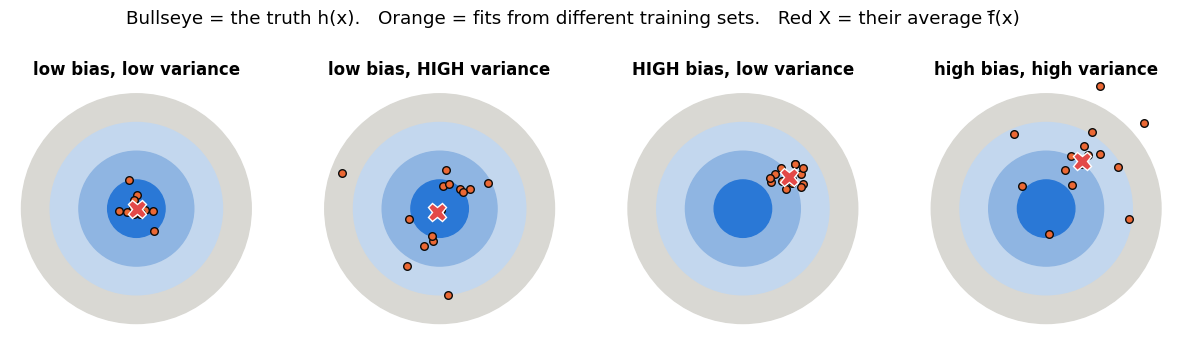

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
r_ = np.random.default_rng(3)
for ax, (b, v, name) in zip(axes, [(0, 0.15, "low bias, low variance"), (0, 0.6, "low bias, HIGH variance"),
                                   (1.0, 0.15, "HIGH bias, low variance"), (1.0, 0.6, "high bias, high variance")]):
    for rad, col in zip([2, 1.5, 1.0, 0.5], [C["light"], "#c3d7ee", "#8fb5e2", C["blue"]]):
        ax.add_patch(plt.Circle((0, 0), rad, color=col, zorder=0))
    pts = r_.normal([b * 0.8, b * 0.6], v, size=(15, 2))
    ax.scatter(*pts.T, s=30, color=C["orange"], edgecolor=C["ink"], zorder=3)
    ax.plot(*pts.mean(0), "X", color=C["red"], ms=13, markeredgecolor="white", zorder=4)
    ax.set(xlim=(-2.2, 2.2), ylim=(-2.2, 2.2), aspect="equal", title=name); ax.axis("off")
fig.suptitle("Bullseye = the truth h(x).   Orange = fits from different training sets.   Red X = their average f̄(x)", y=1.02)
plt.show()

### Simulating the decomposition

The formula has expectations over training sets, which we can't compute exactly for real data. But here we *know* the truth, so we can simulate. Following the classic setup (Bishop's book, and CX 4240 Lecture 6), each training set has $m = 12$ points at evenly spaced $x$ locations, the same locations every time, with **fresh noise** in $y$. We draw 200 such training sets, fit each one, and measure every term directly.

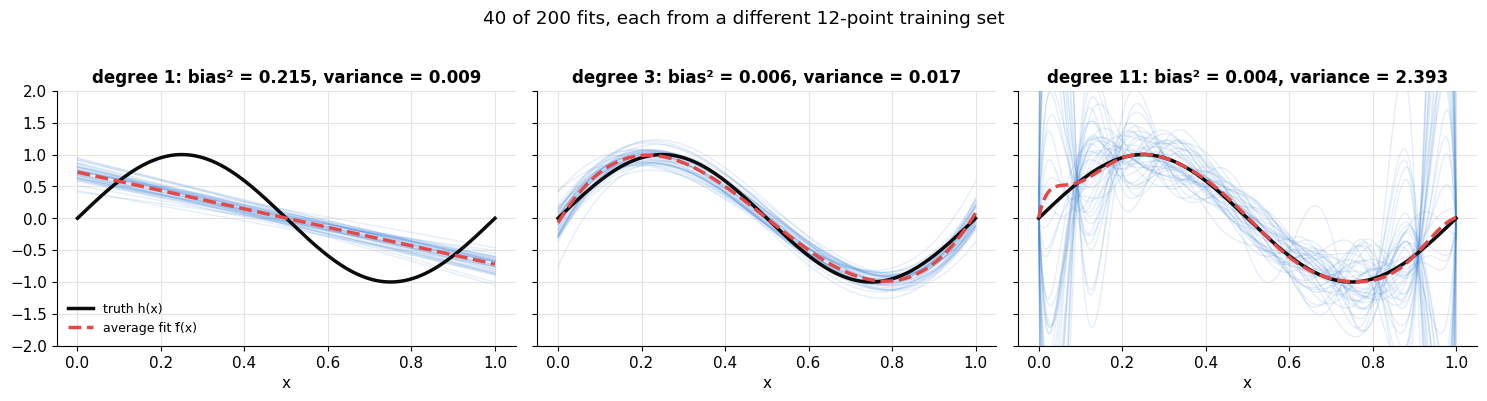

In [5]:
def bias_variance(degree, m=12, n_sets=200, lam=0.0, seed=0, design="fixed"):
    """Monte Carlo estimate of bias², variance and test error at grid points xx.
    design="fixed": the same evenly spaced x's in every training set (only the noise changes);
    design="random": x's drawn uniformly at random each time."""
    r_ = np.random.default_rng(seed)
    preds = np.empty((n_sets, len(xx)))
    test_err = []
    for s in range(n_sets):
        if design == "fixed":
            xt = np.linspace(0, 1, m); yt = f_true(xt) + r_.normal(0, NOISE, m)
        else:
            xt, yt = sample(m, r_)
        th = fit_ridge(poly(xt, degree), yt, lam)
        preds[s] = poly(xx, degree) @ th
        ynew = f_true(xx) + r_.normal(0, NOISE, len(xx))           # fresh test targets at the grid
        test_err.append(np.mean((ynew - preds[s]) ** 2))
    fbar = preds.mean(0)
    bias2 = np.mean((fbar - f_true(xx)) ** 2)
    var = np.mean(preds.var(0))
    return dict(bias2=bias2, var=var, noise=NOISE**2, test=np.mean(test_err), preds=preds, fbar=fbar)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.9), sharey=True)
for ax, d in zip(axes, [1, 3, 11]):
    bv = bias_variance(d)
    for p in bv["preds"][:40]:
        ax.plot(xx, p, color=C["blue"], alpha=0.12, lw=1)
    ax.plot(xx, f_true(xx), color=C["ink"], lw=2.5, label="truth h(x)")
    ax.plot(xx, bv["fbar"], color=C["red"], lw=2.5, ls="--", label="average fit f̄(x)")
    ax.set(ylim=(-2, 2), xlabel="x", title=f"degree {d}: bias² = {bv['bias2']:.3f}, variance = {bv['var']:.3f}")
axes[0].legend(loc="lower left", fontsize=9)
fig.suptitle("40 of 200 fits, each from a different 12-point training set", y=1.02); fig.tight_layout(); plt.show()

- **Degree 1:** the fits barely move (low variance), but their average is a straight line that can't follow the wave (high bias).
- **Degree 11:** 12 coefficients for 12 points, so every fit passes exactly through its noisy points. The *average* fit is nearly perfect (low bias), but individual fits fly all over the place, especially near the edges (high variance).
- **Degree 3:** a good compromise.

Now sweep the degree and check that **bias² + variance + noise** really equals the simulated test error:

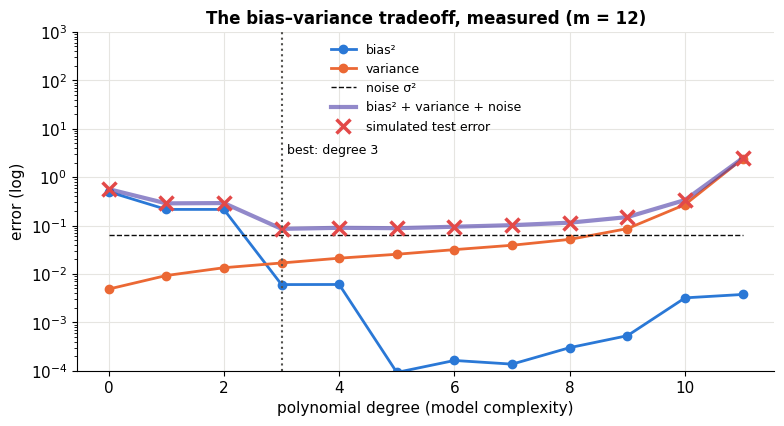

degree,0,1,2,3,4,5,6,7,8,9,10,11
bias2,0.4983,0.2152,0.2152,0.0060,0.0061,0.0001,0.0002,0.0001,0.0003,0.0005,0.0032,0.0038
variance,0.0049,0.0093,0.0134,0.0168,0.0211,0.0255,0.0318,0.0391,0.0517,0.0863,0.2710,2.3931
noise,0.0625,0.0625,0.0625,0.0625,0.0625,0.0625,0.0625,0.0625,0.0625,0.0625,0.0625,0.0625
test,0.5654,0.2866,0.2909,0.0853,0.0898,0.0882,0.0943,0.1014,0.1138,0.1489,0.3354,2.4595
sum,0.5657,0.2869,0.2911,0.0854,0.0897,0.0881,0.0944,0.1018,0.1145,0.1493,0.3367,2.4594


In [6]:
rows = []
for d in range(0, 12):
    bv = bias_variance(d)
    rows.append(dict(degree=d, bias2=bv["bias2"], variance=bv["var"], noise=bv["noise"], test=bv["test"]))
bvdf = pd.DataFrame(rows); bvdf["sum"] = bvdf.bias2 + bvdf.variance + bvdf.noise

fig, ax = plt.subplots(figsize=(9, 4.4))
ax.semilogy(bvdf.degree, bvdf.bias2, "-o", color=C["blue"], label="bias²")
ax.semilogy(bvdf.degree, bvdf.variance, "-o", color=C["orange"], label="variance")
ax.semilogy(bvdf.degree, bvdf.noise, "--", color=C["ink"], lw=1, label="noise σ²")
ax.semilogy(bvdf.degree, bvdf["sum"], "-", color=C["violet"], lw=3, alpha=0.6, label="bias² + variance + noise")
ax.semilogy(bvdf.degree, bvdf.test, "x", color=C["red"], ms=10, mew=2.5, label="simulated test error")
best = int(bvdf.test.idxmin())
ax.axvline(best, color=C["muted"], ls=":", lw=1.5); ax.text(best + 0.1, 3, f"best: degree {best}", fontsize=9)
ax.set(xlabel="polynomial degree (model complexity)", ylabel="error (log)", ylim=(1e-4, 1e3),
       title="The bias–variance tradeoff, measured (m = 12)"); ax.legend(fontsize=9, loc="upper center")
plt.show()
bvdf.round(4).set_index("degree").T

The red crosses (test error measured directly) sit on the purple curve (sum of the three terms): the decomposition checks out. This is the U-shaped curve from every ML textbook, but measured instead of sketched.

🎚️ **Try it yourself.** Change the degree, the training-set size $m$, and the noise. Things to notice:
- With $m = 60$, degree 11 is no longer a disaster: **variance shrinks with more data**, bias doesn't.
- With degree 1, no amount of data helps: the red dashed average stays a straight line.

In [7]:
def plot_bv(degree=3, m=12, noise=0.25):
    global NOISE
    old, NOISE = NOISE, noise
    try:
        bv = bias_variance(degree, m=m, n_sets=120)
    finally:
        NOISE = old
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.9), gridspec_kw=dict(width_ratios=[1.6, 1]))
    for p in bv["preds"][:50]:
        ax1.plot(xx, p, color=C["blue"], alpha=0.12, lw=1)
    ax1.plot(xx, f_true(xx), color=C["ink"], lw=2.5); ax1.plot(xx, bv["fbar"], color=C["red"], lw=2.5, ls="--")
    ax1.set(ylim=(-2, 2), title=f"degree {degree}, m = {m}, noise σ = {noise}")
    parts = [bv["bias2"], bv["var"], noise**2]
    ax2.bar(["bias²", "variance", "noise"], parts, color=[C["blue"], C["orange"], C["muted"]])
    ax2.set(yscale="log", ylim=(1e-4, 20), title=f"test error ≈ {sum(parts):.3f}")
    fig.tight_layout(); plt.show()

interact(plot_bv, degree=IntSlider(value=3, min=0, max=12, description="degree"),
         m=IntSlider(value=12, min=12, max=120, step=4, description="m"),
         noise=FloatSlider(value=0.25, min=0.0, max=1.0, step=0.05, description="noise σ"));

> 🤔 **Question: Is the bias–variance decomposition only for squared error?**
>
> The clean three-way split is specific to squared error. For other losses (like the 0/1 classification error) there are analogous but messier decompositions. The *intuition* carries over everywhere though: rigid models make consistent, systematic mistakes; flexible models make erratic, data-dependent ones.

---
## 4. Bias and variance for ridge regression

Model complexity isn't only "how many parameters." Regularization controls it too. Fix the degree at 11 (as flexible as 12 points allow) and sweep ridge's $\lambda$ instead:

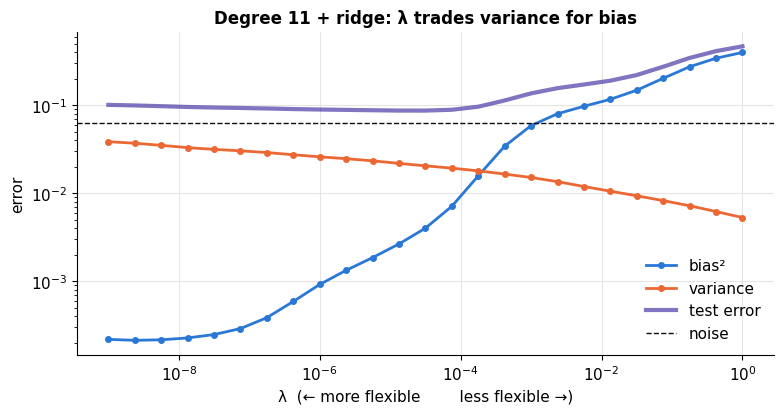

In [8]:
lams = np.logspace(-9, 0, 25)
rows = [dict(lam=l, **{k: v for k, v in bias_variance(11, lam=l, n_sets=150).items() if k in ("bias2", "var", "test")}) for l in lams]
rdf = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.loglog(rdf.lam, rdf.bias2, "-o", color=C["blue"], ms=4, label="bias²")
ax.loglog(rdf.lam, rdf["var"], "-o", color=C["orange"], ms=4, label="variance")
ax.loglog(rdf.lam, rdf.test, "-", color=C["violet"], lw=3, alpha=0.7, label="test error")
ax.axhline(NOISE**2, color=C["ink"], ls="--", lw=1, label="noise")
ax.set(xlabel="λ  (← more flexible        less flexible →)", ylabel="error", title="Degree 11 + ridge: λ trades variance for bias")
ax.legend(); plt.show()

It's the same tradeoff, mirrored: small $\lambda$ = flexible = low bias, high variance; large $\lambda$ = rigid = high bias, low variance. This is why **every** flexible model in this series comes with a knob like this (tree depth, number of neighbors $k$, network width, dropout, early stopping...). And every one of those knobs needs to be **chosen**, which is what cross-validation is for.

---
## 5. Why complex models also become numerically unstable

ISYE 4600 (W6) points out a third problem with high-degree polynomials, separate from statistics: **numerical instability**. The columns $1, x, x^2, \dots, x^d$ become nearly parallel for large $d$ (on $[0,1]$, $x^8$ and $x^9$ look almost identical). So $X^\top X$ is nearly singular, its **condition number** explodes, and small rounding errors get amplified into large changes in $\hat\theta$.

And once $d + 1 > m$ (more coefficients than points), $\text{rank}(X^\top X) \le m < d+1$, so it's **exactly** singular: infinitely many polynomials pass through the points.

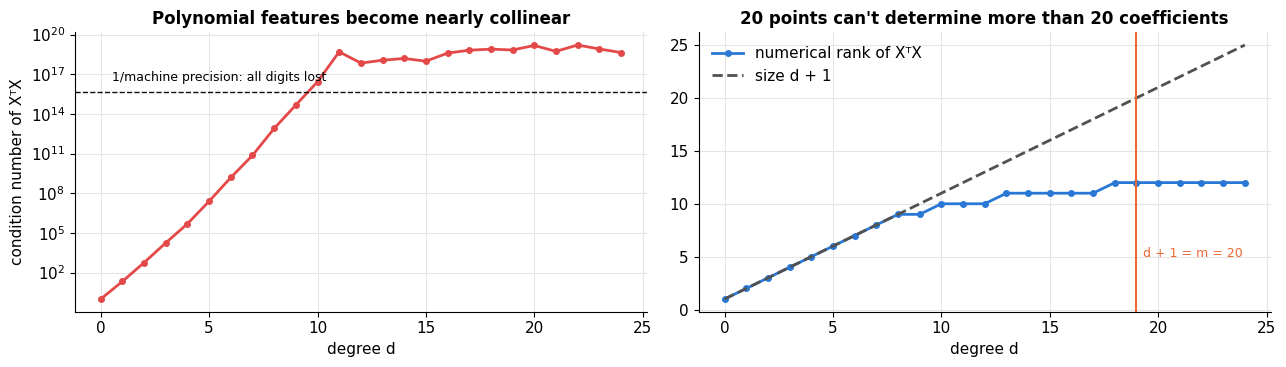

In [9]:
xs20 = np.sort(np.random.default_rng(1).uniform(0, 1, 20))
conds = [np.linalg.cond(poly(xs20, d).T @ poly(xs20, d)) for d in range(0, 25)]
ranks = [np.linalg.matrix_rank(poly(xs20, d).T @ poly(xs20, d)) for d in range(0, 25)]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))
ax1.semilogy(range(25), conds, "-o", color=C["red"], ms=4)
ax1.axhline(1 / np.finfo(float).eps, color=C["ink"], ls="--", lw=1); ax1.text(0.5, 3e16, "1/machine precision: all digits lost", fontsize=9)
ax1.set(xlabel="degree d", ylabel="condition number of XᵀX", title="Polynomial features become nearly collinear")
ax2.plot(range(25), ranks, "-o", color=C["blue"], ms=4, label="numerical rank of XᵀX")
ax2.plot(range(25), [d + 1 for d in range(25)], "--", color=C["muted"], label="size d + 1")
ax2.axvline(19, color=C["orange"], lw=1.5); ax2.text(19.3, 5, "d + 1 = m = 20", fontsize=9, color=C["orange"])
ax2.set(xlabel="degree d", title="20 points can't determine more than 20 coefficients"); ax2.legend()
fig.tight_layout(); plt.show()

Ridge's $+\lambda m I$ fixes both issues at once (every eigenvalue gets at least $\lambda m$, so the condition number stays bounded). In practice, people also use better-conditioned bases, like orthogonal (Legendre/Chebyshev) polynomials or splines, instead of raw powers $x^j$.

---
## 6. Holding out data: train / validation / test

In real life we don't know $h(x)$ and can't draw 200 fresh training sets. We have one dataset. The simplest honest approach is to split it:

- **Training set**: fit the parameters $\theta$.
- **Validation set**: compare models / choose hyperparameters (degree, $\lambda$).
- **Test set**: evaluate the final chosen model **once**, at the very end.

The catch: with limited data, a single split is **noisy**. Here's the validation estimate of test error for degree 3, from 300 different random 70/30 splits of the same 30 points:

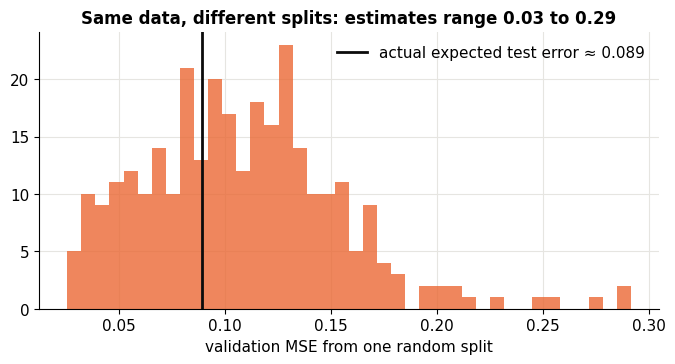

In [10]:
r_ = np.random.default_rng(5)
x30, y30 = sample(30, r_)
def holdout_mse(degree, x, y, frac=0.7, seed=0):
    p = np.random.default_rng(seed).permutation(len(x)); k = int(frac * len(x))
    tr, va = p[:k], p[k:]
    th = fit_ridge(poly(x[tr], degree), y[tr])
    return np.mean((poly(x[va], degree) @ th - y[va]) ** 2)

ests = np.array([holdout_mse(3, x30, y30, seed=s) for s in range(300)])
true_err = bias_variance(3, m=21, n_sets=300, design="random")["test"]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(ests, bins=40, color=C["orange"], alpha=0.8)
ax.axvline(true_err, color=C["ink"], lw=2, label=f"actual expected test error ≈ {true_err:.3f}")
ax.set(xlabel="validation MSE from one random split", title=f"Same data, different splits: estimates range {ests.min():.2f} to {ests.max():.2f}")
ax.legend(); plt.show()

Depending on which 9 points land in the validation set, the estimate varies several-fold. And we only trained on 70% of the data, so we also wasted data. K-fold cross-validation (section 8) fixes both problems by **rotating** the validation set and averaging. But first, a tool for diagnosing what's wrong with a model.

---
## 7. Learning curves: is more data going to help?

Collecting data is expensive. Before you do it, check whether it would help. A **learning curve** plots training and validation error against the training-set size $m$:

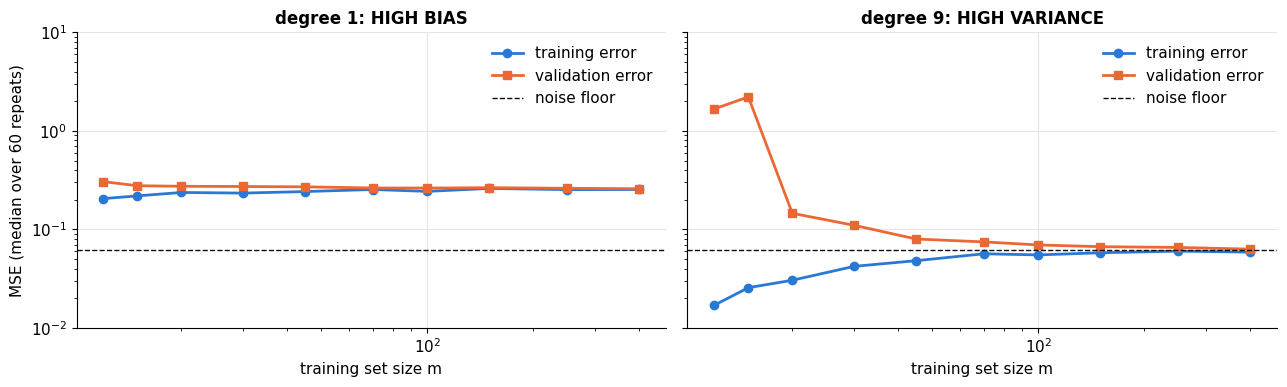

In [11]:
def learning_curve(degree, ms, reps=60, seed=0):
    r_ = np.random.default_rng(seed); tr, va = [], []
    for m_ in ms:
        a, b = [], []
        for _ in range(reps):
            xt, yt = sample(m_, r_); xv, yv = sample(200, r_)
            th = fit_ridge(poly(xt, degree), yt, lam=1e-12)
            a.append(np.mean((poly(xt, degree) @ th - yt) ** 2)); b.append(np.mean((poly(xv, degree) @ th - yv) ** 2))
        tr.append(np.median(a)); va.append(np.median(b))
    return np.array(tr), np.array(va)

ms = np.array([12, 15, 20, 30, 45, 70, 100, 150, 250, 400])
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, d, name in [(axes[0], 1, "degree 1: HIGH BIAS"), (axes[1], 9, "degree 9: HIGH VARIANCE")]:
    tr, va = learning_curve(d, ms)
    ax.semilogy(ms, tr, "-o", color=C["blue"], label="training error"); ax.semilogy(ms, va, "-s", color=C["orange"], label="validation error")
    ax.axhline(NOISE**2, color=C["ink"], ls="--", lw=1, label="noise floor")
    ax.set(xscale="log", xlabel="training set size m", title=name, ylim=(1e-2, 10)); ax.legend()
axes[0].set_ylabel("MSE (median over 60 repeats)"); fig.tight_layout(); plt.show()

How to read them:

- **High bias (left):** both curves converge quickly to a level **well above** the noise floor. More data won't help: the model is too simple. Use a more flexible model or better features.
- **High variance (right):** a big **gap** between training and validation error that closes as $m$ grows. More data helps; so would regularization or a simpler model.

> 🤔 **Question: Why does training error go *up* with more data?**
>
> With few points, a flexible model can thread through all of them (training error ≈ 0). Every extra point is one more constraint to satisfy, so it becomes harder to fit them all perfectly. Training error rises toward the noise floor from below while validation error falls toward it from above. They meet in the middle when the model has enough data.

---
## 8. K-fold cross-validation

**K-fold CV** (ISYE 4600 W6) uses *all* the training data for both fitting and validation:

1. Split the training data into $K$ equal **folds**.
2. For $k = 1, \dots, K$: fit on the other $K-1$ folds, compute the error on fold $k$.
3. The **CV error** is the average of the $K$ validation errors.

Every point gets used for validation exactly once and for training $K-1$ times. The test set is set aside **before** any of this and never enters the loop.

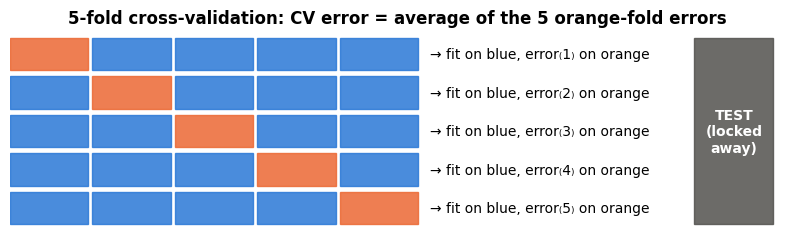

In [12]:
K = 5
fig, ax = plt.subplots(figsize=(10, 2.6))
for k in range(K):
    for j in range(K):
        ax.add_patch(plt.Rectangle((j, K - 1 - k), 0.95, 0.85, color=C["orange"] if j == k else C["blue"], alpha=0.85))
    ax.text(K + 0.1, K - 1 - k + 0.4, f"→ fit on blue, error₍{k+1}₎ on orange", va="center", fontsize=10)
ax.add_patch(plt.Rectangle((K + 3.3, 0), 0.95, K - 0.15, color=C["muted"], alpha=0.85))
ax.text(K + 3.78, K / 2 - 0.1, "TEST\n(locked\naway)", ha="center", va="center", color="white", fontsize=10, fontweight="bold")
ax.set(xlim=(0, K + 4.4), ylim=(-0.2, K)); ax.axis("off")
ax.set_title("5-fold cross-validation: CV error = average of the 5 orange-fold errors")
plt.show()

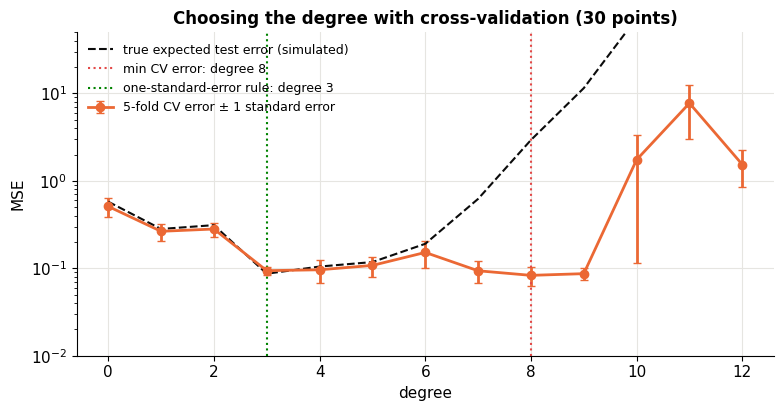

In [13]:
def kfold_indices(m, K, seed=0):
    p = np.random.default_rng(seed).permutation(m)
    return np.array_split(p, K)

def cv_error(fit, predict, X, y, K=5, seed=0):
    """Generic K-fold CV: fit(X, y) -> model, predict(model, X) -> yhat. Returns (mean, per-fold errors)."""
    folds = kfold_indices(len(y), K, seed)
    errs = []
    for k in range(K):
        va = folds[k]; tr = np.concatenate([folds[j] for j in range(K) if j != k])
        model = fit(X[tr], y[tr])
        errs.append(np.mean((predict(model, X[va]) - y[va]) ** 2))
    return np.mean(errs), np.array(errs)

# Choose the polynomial degree for our 30 points by 5-fold CV
cv_means, cv_ses = [], []
for d in range(0, 13):
    mean_, errs = cv_error(lambda X_, y_: fit_ridge(poly(X_, d), y_), lambda th, X_: poly(X_, d) @ th, x30, y30, K=5)
    cv_means.append(mean_); cv_ses.append(errs.std(ddof=1) / np.sqrt(len(errs)))
cv_means, cv_ses = np.array(cv_means), np.array(cv_ses)
true_curve = [bias_variance(d, m=24, n_sets=150, design="random")["test"] for d in range(0, 13)]

best_d = int(np.argmin(cv_means))
one_se_d = int(np.min(np.where(cv_means <= cv_means[best_d] + cv_ses[best_d])[0]))
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.errorbar(range(13), cv_means, yerr=cv_ses, fmt="-o", color=C["orange"], capsize=3, label="5-fold CV error ± 1 standard error")
ax.plot(range(13), true_curve, "--", color=C["ink"], lw=1.5, label="true expected test error (simulated)")
ax.axvline(best_d, color=C["red"], ls=":", lw=1.5, label=f"min CV error: degree {best_d}")
ax.axvline(one_se_d, color=C["green"], ls=":", lw=1.5, label=f"one-standard-error rule: degree {one_se_d}")
ax.set(yscale="log", ylim=(1e-2, 50), xlabel="degree", ylabel="MSE", title="Choosing the degree with cross-validation (30 points)"); ax.legend(fontsize=9)
plt.show()

The CV curve tracks the true (simulated) test-error curve well, using nothing but the 30 points we have. Two common ways to read it:

- **Pick the minimum.**
- **The one-standard-error rule:** pick the *simplest* model whose CV error is within one standard error of the minimum. The CV curve is itself noisy, so differences smaller than its error bars are not meaningful, and when in doubt, simpler models generalize more reliably.

Here the two rules disagree, which is instructive: the minimum landed on degree 8, but the true error curve (dashed) shows degree 8 is actually much worse than degree 3. The CV error at degrees 7–9 happened to come out low on this particular sample, and its error bars overlap degree 3's. The one-standard-error rule picks degree 3, the better model. That's exactly the situation the rule is designed for.

After choosing, **refit the chosen model on all the training data** (all $K$ folds), then evaluate it once on the test set.

### Choosing ridge's λ on real data

ISYE 4600 (W6) does exactly this on the diabetes data from notebook 05. Note the care taken with standardization: it's fit **inside** each fold on that fold's training part only.

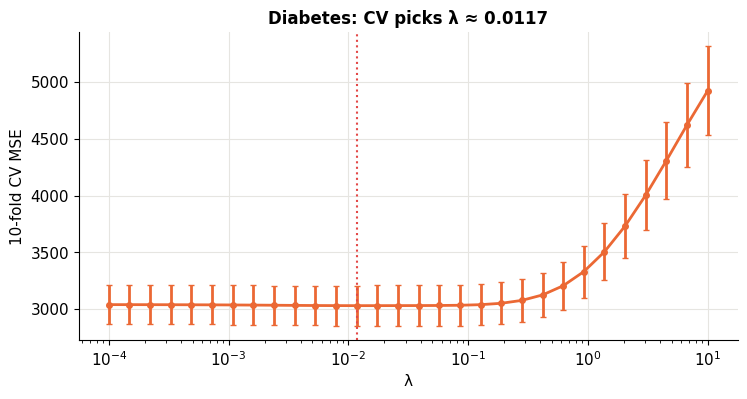

Test MSE, plain least squares: 2898
Test MSE, ridge with CV-chosen λ: 2890


In [14]:
D = load_diabetes(scaled=False)
Xd, yd = D.data, D.target
p = np.random.default_rng(0).permutation(len(yd)); test_idx, train_idx = p[:110], p[110:]
Xtr, ytr, Xte, yte = Xd[train_idx], yd[train_idx], Xd[test_idx], yd[test_idx]

def fit_std_ridge(lam):
    def fit(X_, y_):
        mu, sd = X_.mean(0), X_.std(0)                 # standardization learned on the fold's TRAINING part
        th = fit_ridge(np.column_stack([np.ones(len(X_)), (X_ - mu) / sd]), y_, lam)
        return mu, sd, th
    return fit
predict_std = lambda model, X_: np.column_stack([np.ones(len(X_)), (X_ - model[0]) / model[1]]) @ model[2]

lams_d = np.logspace(-4, 1, 30)
res = [cv_error(fit_std_ridge(l), predict_std, Xtr, ytr, K=10) for l in lams_d]
cvm = np.array([r[0] for r in res]); cvs = np.array([r[1].std(ddof=1) / np.sqrt(10) for r in res])
best_lam = lams_d[np.argmin(cvm)]

final = fit_std_ridge(best_lam)(Xtr, ytr)                # refit on ALL training data
ols = fit_std_ridge(0.0)(Xtr, ytr)
mse_te = lambda model: np.mean((predict_std(model, Xte) - yte) ** 2)

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.errorbar(lams_d, cvm, yerr=cvs, fmt="-o", ms=4, color=C["orange"], capsize=2)
ax.axvline(best_lam, color=C["red"], ls=":", lw=1.5)
ax.set(xscale="log", xlabel="λ", ylabel="10-fold CV MSE", title=f"Diabetes: CV picks λ ≈ {best_lam:.3g}")
plt.show()
print(f"Test MSE, plain least squares: {mse_te(ols):.0f}")
print(f"Test MSE, ridge with CV-chosen λ: {mse_te(final):.0f}")

On this dataset the improvement from ridge is small: with 330 training points and only 10 features, plain least squares wasn't badly overfitting to begin with (the learning-curve lesson again: variance shrinks with data). Regularization matters most when features are many relative to examples, which is notebook 07's territory.

> 🤔 **Question: How do I choose $K$?**
>
> $K = 5$ or $10$ is the standard choice. Larger $K$ means each model trains on more data (less pessimistic estimate) but costs $K$ fits and the folds overlap more. $K = m$ is **leave-one-out CV (LOOCV)**. For linear smoothers like least squares and ridge, LOOCV has a magic shortcut that needs only **one** fit: the leave-one-out residual is $\frac{y^i - \hat y^i}{1 - H_{ii}}$, using the hat matrix from notebook 05. Check it:

In [15]:
d = 3
Phi = poly(x30, d); H = Phi @ np.linalg.solve(Phi.T @ Phi, Phi.T)
loo_shortcut = np.mean(((y30 - H @ y30) / (1 - np.diag(H))) ** 2)
loo_brute = cv_error(lambda X_, y_: fit_ridge(poly(X_, d), y_), lambda th, X_: poly(X_, d) @ th, x30, y30, K=30)[0]
print(f"LOOCV by brute force (30 fits): {loo_brute:.6f}")
print(f"LOOCV by the hat-matrix shortcut (1 fit): {loo_shortcut:.6f}")

LOOCV by brute force (30 fits): 0.096848
LOOCV by the hat-matrix shortcut (1 fit): 0.096848


---
## 9. Data leakage: how to get 90% "accuracy" on pure noise

Cross-validation is only honest if **everything** that learns from data happens inside the folds. "Everything" includes preprocessing steps people don't think of as learning: feature selection, standardization, imputing missing values, choosing which outliers to drop.

Here's the classic trap, from *The Elements of Statistical Learning* (Section 7.10.2). We make a dataset that is **pure noise**: 50 examples, 5,000 random features, and a target that is unrelated to all of them. Then:

- **The wrong way:** pick the 20 features most correlated with $y$ using **all** the data, then cross-validate a regression on those 20.
- **The right way:** do the feature selection **inside** each fold, using only that fold's training part.

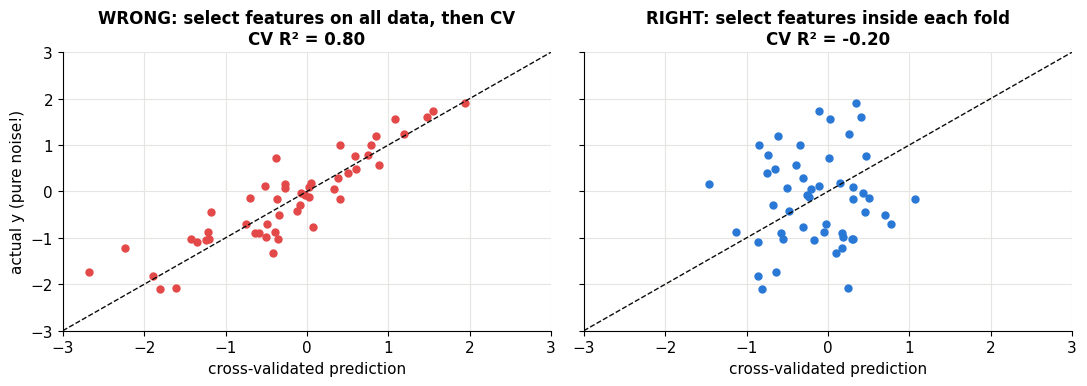

In [16]:
r_ = np.random.default_rng(11)
m_noise, p_noise = 50, 5000
Xn = r_.normal(size=(m_noise, p_noise))
yn = r_.normal(size=m_noise)                   # unrelated to Xn: the best possible R² is 0

def top_k_corr(X_, y_, k=20):
    Xc, yc = X_ - X_.mean(0), y_ - y_.mean()
    corr = (Xc * yc[:, None]).sum(0) / (np.linalg.norm(Xc, axis=0) * np.linalg.norm(yc))
    return np.argsort(-np.abs(corr))[:k]

def cv_r2(X_, y_, select_inside, K=5, seed=0):
    folds = kfold_indices(len(y_), K, seed); sel_all = top_k_corr(X_, y_)
    preds = np.empty_like(y_)
    for k in range(K):
        va = folds[k]; tr = np.concatenate([folds[j] for j in range(K) if j != k])
        sel = top_k_corr(X_[tr], y_[tr]) if select_inside else sel_all      # ← the only difference
        A = np.column_stack([np.ones(len(tr)), X_[tr][:, sel]])
        th = np.linalg.lstsq(A, y_[tr], rcond=None)[0]
        preds[va] = np.column_stack([np.ones(len(va)), X_[va][:, sel]]) @ th
    return 1 - np.sum((y_ - preds) ** 2) / np.sum((y_ - y_.mean()) ** 2), preds

r2_wrong, p_wrong = cv_r2(Xn, yn, select_inside=False)
r2_right, p_right = cv_r2(Xn, yn, select_inside=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, pr, r2v, name in [(axes[0], p_wrong, r2_wrong, "WRONG: select features on all data, then CV"),
                          (axes[1], p_right, r2_right, "RIGHT: select features inside each fold")]:
    ax.scatter(pr, yn, s=25, color=C["red"] if pr is p_wrong else C["blue"])
    ax.plot([-3, 3], [-3, 3], color=C["ink"], ls="--", lw=1)
    ax.set(xlim=(-3, 3), ylim=(-3, 3), xlabel="cross-validated prediction", title=f"{name}\nCV R² = {r2v:.2f}")
axes[0].set_ylabel("actual y (pure noise!)"); fig.tight_layout(); plt.show()

The wrong way reports a strong positive $R^2$ on data where the truth is "nothing can be predicted." What happened: with 5,000 random features, *some* of them correlate with $y$ by pure chance, **including on the validation folds**, because they were selected by looking at the validation points' $y$ values. The validation folds weren't really unseen. The right way gives an $R^2$ at or below 0, the honest answer.

The general rule: **anything fit to data is part of the model, and must be fit on training folds only.** Common leaks:

| Leak | Fix |
|---|---|
| Standardizing / scaling with statistics from all data | fit the scaler on the training fold (scikit-learn's `Pipeline` does this automatically) |
| Feature selection on all data | select inside each fold |
| Tuning hyperparameters on the test set | use CV on the training set; touch test once |
| Duplicates or near-duplicates across splits (same patient, same user) | split by **group** (`GroupKFold`) |
| Time series: training on the future, validating on the past | split by **time** (`TimeSeriesSplit`) |
| A feature that's really a proxy for the label (e.g. "treatment given" when predicting the disease) | think hard about what's known at prediction time |

> 🤔 **Question: Did that table's last row really happen in practice?**
>
> All the time. A famous example: models that "detected" pneumonia from chest X-rays partly by recognizing which hospital's scanner took the image, because the hospitals had different pneumonia rates. Cross-validation can't catch leaks like this when the leak is in every fold; you have to reason about where the data came from.

---
## 10. Beyond the U-curve: double descent

The U-shaped curve says test error must rise once a model gets flexible enough to interpolate the data. But modern neural networks have far more parameters than training examples, fit their training data perfectly, and still generalize. What gives?

A small linear experiment reproduces the phenomenon. The data has $D = 400$ Gaussian features, and the true coefficients decay ($\beta_j \propto 1/j$: a few features matter a lot, many matter a little). We have only $m = 40$ training examples. The model uses the **first $p$ features** and fits least squares. Once $p > m$ there are infinitely many coefficient vectors that fit the training data perfectly; we take the one with the **smallest norm** (what `lstsq` and the pseudo-inverse return, and also what gradient descent started from zero converges to).

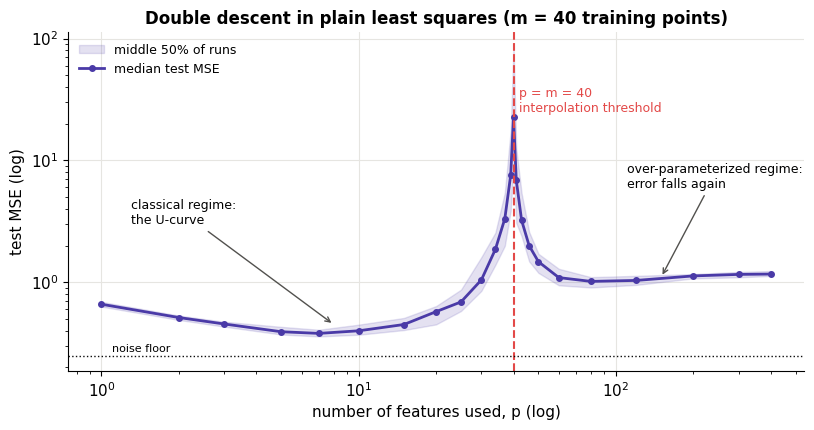

In [17]:
def double_descent(ps, D=400, m=40, noise=0.5, reps=60, seed=0):
    r_ = np.random.default_rng(seed)
    beta = 1 / np.arange(1, D + 1); beta /= np.linalg.norm(beta)
    med, q25, q75 = [], [], []
    for p_ in ps:
        errs = []
        for _ in range(reps):
            Xt = r_.normal(size=(m, D)); yt = Xt @ beta + r_.normal(0, noise, m)
            Xv = r_.normal(size=(500, D)); yv = Xv @ beta + r_.normal(0, noise, 500)
            th = np.linalg.lstsq(Xt[:, :p_], yt, rcond=None)[0]          # min-norm solution when p > m
            errs.append(np.mean((Xv[:, :p_] @ th - yv) ** 2))
        med.append(np.median(errs)); q25.append(np.percentile(errs, 25)); q75.append(np.percentile(errs, 75))
    return np.array(med), np.array(q25), np.array(q75)

ps = np.array([1, 2, 3, 5, 7, 10, 15, 20, 25, 30, 34, 37, 39, 40, 41, 43, 46, 50, 60, 80, 120, 200, 300, 400])
med, q25, q75 = double_descent(ps)
fig, ax = plt.subplots(figsize=(9.5, 4.4))
ax.fill_between(ps, q25, q75, color=C["violet"], alpha=0.15, label="middle 50% of runs")
ax.plot(ps, med, "-o", color=C["violet"], ms=4, label="median test MSE")
ax.axvline(40, color=C["red"], ls="--", lw=1.5); ax.text(42, 25, "p = m = 40\ninterpolation threshold", fontsize=9, color=C["red"])
ax.axhline(0.25, color=C["ink"], ls=":", lw=1); ax.text(1.1, 0.27, "noise floor", fontsize=8)
ax.annotate("classical regime:\nthe U-curve", (8, 0.45), xytext=(1.3, 3), fontsize=9, arrowprops=dict(arrowstyle="->", color=C["muted"]))
ax.annotate("over-parameterized regime:\nerror falls again", (150, 1.1), xytext=(110, 6), fontsize=9, arrowprops=dict(arrowstyle="->", color=C["muted"]))
ax.set(xscale="log", yscale="log", xlabel="number of features used, p (log)", ylabel="test MSE (log)", title="Double descent in plain least squares (m = 40 training points)")
ax.legend(loc="upper left", fontsize=9); plt.show()

Left of the red line is the classic U-curve: a few features underfit, more help, then variance takes over. Exactly at $p = m$ there is precisely **one** coefficient vector that fits all 40 noisy points, and it has to contort itself to do so: enormous coefficients, enormous variance, and the test error spikes by a factor of ~50. But past the threshold the error **comes back down**. With many more features than points there are many perfect fits, and the minimum-norm one spreads the weight thinly across lots of features instead of piling it onto a few. Keeping the norm small acts like an *implicit* ridge penalty.

This is **double descent** (Belkin et al., 2019; Hastie et al., 2022). Two things to take away:

- It doesn't contradict the bias–variance decomposition, which is an identity and always holds. It shows that **"number of parameters" is a poor measure of complexity**. What matters is the effective flexibility of the solution your *training procedure* actually finds.
- Whether the second descent ends up *below* the first minimum depends on the problem. Here it doesn't quite (the small-$p$ models win). In large neural networks it often does, which is part of why "just make the model bigger" has worked so well. Part 3 comes back to this.

---
## 11. Summary

| Concept | Key fact |
|---|---|
| Training error | optimistic; always falls with complexity |
| Best predictor | $h(x) = \mathbb{E}[y\mid x]$; its error is the irreducible noise |
| Decomposition | expected test error = bias² + variance + noise |
| Bias | rigid models; more data doesn't help |
| Variance | flexible models; more data, regularization or simpler models help |
| Learning curves | gap ⇒ variance; both high and flat ⇒ bias |
| K-fold CV | average error over $K$ rotations; choose, then refit on everything |
| One-SE rule | pick the simplest model within one SE of the best |
| Leakage | anything fit to data goes inside the folds |
| Double descent | parameter count ≠ complexity; min-norm interpolation can generalize |

### ✏️ Exercises

1. In the bias–variance slider, set the noise to 0. What happens to the best degree as $m$ grows? Why does degree 12 eventually become fine?
2. Repeat section 4 with **lasso**-style shrinkage replaced by **early stopping**: run gradient descent on the degree-9 model and treat the number of steps as the complexity knob. Do you get the same U-shape?
3. Show that the LOOCV shortcut is exact. *(Hint: the Sherman–Morrison formula for a rank-one update of $X^\top X$.)*
4. Redo the leakage experiment with 500 features instead of 5,000. Does the wrong-way $R^2$ shrink? What about 50,000?
5. Build a nested cross-validation: an outer 5-fold loop to estimate test error, and inside each outer fold, an inner 5-fold loop to choose $\lambda$. Why is the outer estimate more honest than the inner one?
6. In the double-descent experiment, add a small ridge penalty to the fit. What happens to the peak at $p = m$? (This is why the spike rarely shows up in practice: almost everyone regularizes a little.)

### References

- ISYE 4600 W6 (Bias–Variance Tradeoff & Cross Validation): optimal predictor, decomposition, K-fold CV, ridge/Lasso on diabetes; HW2 Q1.
- CX 4240 Lecture 6 (overfitting with polynomial degree; MLE vs. MAP).
- T. Hastie, R. Tibshirani & J. Friedman, *The Elements of Statistical Learning*, Chapter 7 (especially 7.3 and 7.10.2, "The wrong and right way to do cross-validation").
- S. Geman, E. Bienenstock & R. Doursat, *Neural Networks and the Bias/Variance Dilemma*, Neural Computation (1992).
- M. Belkin, D. Hsu, S. Ma & S. Mandal, *Reconciling modern machine-learning practice and the classical bias–variance trade-off*, PNAS (2019).
- S. Kaufman et al., *Leakage in Data Mining: Formulation, Detection, and Avoidance*, ACM TKDD (2012).

**Next → [07 · Regularization & Feature Selection](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/07_regularization_feature_selection.ipynb)**